# Example-23: FFT spectral entropy

In [1]:
# In this example, an illustration of the FFT spectral entropy indicator is presented
# The mapping, observable, initial grid, iteration count and plotting follow the SVD entropy example
# Instead of a Hankel matrix and its singular values, the indicator uses the one-sided FFT power spectrum
# The time series is standardized and multiplied by a cosine window before the FFT
# The Shannon entropy of the normalized spectral power is divided by log2(number of frequency bins)

In [2]:
import numpy

import jax
from jax import vmap
from jax import jit

from matplotlib import pyplot as plt
from matplotlib import colormaps

cmap = colormaps.get_cmap('turbo').copy()
cmap.set_bad(color='lightgray')

from tqdm import tqdm

from tohubohu.util import forward4D
from tohubohu import cosine
from tohubohu import fft

In [3]:
# Set data type

jax.config.update("jax_enable_x64", False)

In [4]:
# Set device

device, *_ = jax.devices('cpu')
jax.config.update('jax_default_device', device)

In [5]:
def observable(orbit):
    qx, qy, px, py = orbit.T
    
    mqx = jax.numpy.mean(qx)
    mpx = jax.numpy.mean(px)
    mqy = jax.numpy.mean(qy)
    mpy = jax.numpy.mean(py)
    
    sqx = jax.numpy.std(qx)
    spx = jax.numpy.std(px)
    sqy = jax.numpy.std(qy)
    spy = jax.numpy.std(py)

    return 0.5*(((qx - mqx)/sqx)**2 + ((px - mpx)/spx)**2) + 0.5*(((qy - mqy)/sqy)**2 + ((py - mpy)/spy)**2)

In [6]:
# Set mapping parameters

nux, nuy = 0.168, 0.201
mux, muy = 2*jax.numpy.pi*nux, 2*jax.numpy.pi*nuy
cx, sx, cy, sy = jax.numpy.cos(mux), jax.numpy.sin(mux), jax.numpy.cos(muy), jax.numpy.sin(muy)
mu = 0.0

k = jax.numpy.asarray([cx, sx, cy, sy, mu])

In [7]:
# Construct the window for 4096 iterations, as in the SVD entropy example

weights = cosine(2**12)

In [8]:
%%time

# Construct indicator

x = jax.numpy.array([0.0, 0.0, 0.0, 0.0])
fn = jit(fft(weights, forward4D, observable, background=1.0E-12))
_ = fn(x, k).block_until_ready()

CPU times: user 469 ms, sys: 69.8 ms, total: 539 ms
Wall time: 113 ms


In [9]:
# Set initial grid in (qx, qy) plane

n = 1001

qx = jax.numpy.linspace(0.0, 0.6, n)
qy = jax.numpy.linspace(0.0, 0.6, n)
qs = jax.numpy.stack(jax.numpy.meshgrid(qx, qy, indexing='ij')).swapaxes(-1, 0).reshape(n*n, -1)
ps = jax.numpy.full_like(qs, 1.0E-12)
xs = jax.numpy.hstack([qs, ps])
xs = jax.numpy.array_split(xs, n)

In [10]:
# Evaluate indicator

xb, *xr = xs
fj = jit(vmap(fn, (0, None)))
out = [fj(xb, k)]

for xb in tqdm(xr):
    out.append(fj(xb, k))
out = jax.numpy.concatenate(out)

# Winsorize data

data = numpy.array(out)
data = data.reshape(n, n)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [01:46<00:00,  9.41it/s]


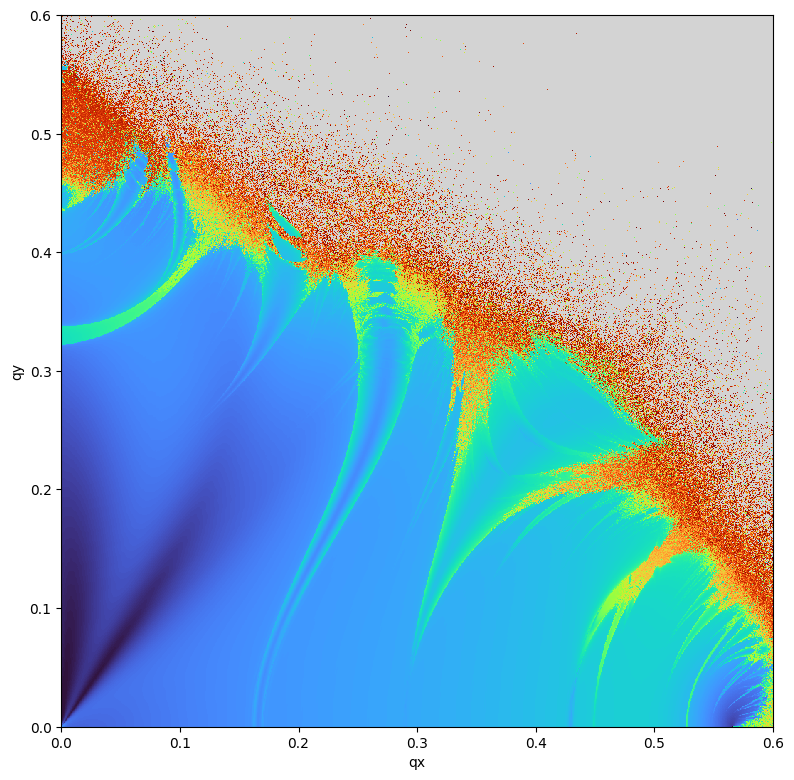

In [11]:
# Plot 

plt.figure(figsize=(8, 8))
plt.imshow(data, aspect='equal', vmin=0.2, vmax=0.8, origin='lower', cmap=cmap, interpolation='nearest', extent=(0., 0.6, 0., 0.6))
plt.xlabel('qx')
plt.ylabel('qy')
plt.tight_layout()
plt.show()